<a href="https://colab.research.google.com/github/divyadharshiniug/24ADI006L_24BAD023/blob/main/24AD023_DL_EX_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name    : Divyadharshini U G
Roll No : 24BAD023
TensorFlow version: 2.21.0
--------------------------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape : (60000, 28, 28)
Training labels shape : (60000,)
Testing images shape  : (10000, 28, 28)
Testing labels shape  : (10000,)
Data type of images   : uint8
Pixel value range     : min = 0 , max = 255
Number of classes     : 10
--------------------------------------------------
After normalization   : min = -1.0 , max = 1.0
Data type after       : float32
--------------------------------------------------
Reshaped training shape : (60000, 28, 28, 1)
Reshaped testing shape  : (10000, 28, 28, 1)
--------------------------------------------------
Batch size            : 256
Batches per epoch     : 235


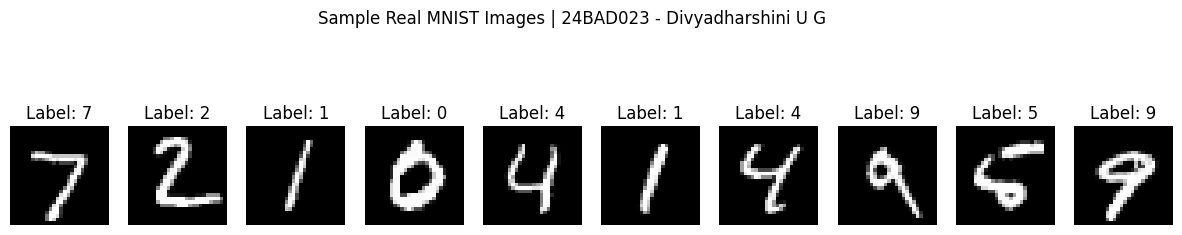

In [1]:
# ============================================================
# EXPT 8 - Generation of Synthetic Images using a GAN
# PART A: DATASET PREPARATION
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("TensorFlow version:", tf.__version__)
print("-" * 50)

# 1. Load the MNIST dataset (already split into train and test)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Explore the dataset
print("Training images shape :", x_train.shape)
print("Training labels shape :", y_train.shape)
print("Testing images shape  :", x_test.shape)
print("Testing labels shape  :", y_test.shape)
print("Data type of images   :", x_train.dtype)
print("Pixel value range     : min =", x_train.min(), ", max =", x_train.max())
print("Number of classes     :", len(np.unique(y_train)))
print("-" * 50)

# 3. Normalize pixel values to the range -1 to 1
#    (matches the tanh activation in the Generator's output layer)
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_test = (x_test.astype("float32") - 127.5) / 127.5
print("After normalization   : min =", x_train.min(), ", max =", x_train.max())
print("Data type after       :", x_train.dtype)

# 4. Reshape images to 28x28x1 (channel dimension for Conv layers)
x_train = x_train.reshape((-1, 28, 28, 1))
x_test = x_test.reshape((-1, 28, 28, 1))
print("-" * 50)
print("Reshaped training shape :", x_train.shape)
print("Reshaped testing shape  :", x_test.shape)

# 5. Prepare batches of real images for GAN training
BUFFER_SIZE = 60000
BATCH_SIZE = 256
train_dataset = (tf.data.Dataset.from_tensor_slices(x_train)
                 .shuffle(BUFFER_SIZE)
                 .batch(BATCH_SIZE))
print("-" * 50)
print("Batch size            :", BATCH_SIZE)
print("Batches per epoch     :", len(train_dataset))

# 6. Display a sample of the original (real) images
n = 10
plt.figure(figsize=(15, 3))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28) * 127.5 + 127.5, cmap="gray")
    plt.title(f"Label: {y_test[i]}")
    plt.axis("off")
plt.suptitle("Sample Real MNIST Images | 24BAD023 - Divyadharshini U G", y=1.05)
plt.show()

Name    : Divyadharshini U G
Roll No : 24BAD023
--------------------------------------------------
Loss function : Binary Cross-Entropy (from logits)
Optimizer     : Adam (lr = 0.0001, beta_1 = 0.5)
--------------------------------------------------
GENERATOR SUMMARY


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

... (9 outputs left out)

 Total params: 2,543,810 (9.70 MB)

 Trainable params: 2,518,338 (9.61 MB)

 Non-trainable params: 25,472 (99.50 KB)

--------------------------------------------------
Generated image shape        : (1, 28, 28, 1)
Discriminator score (logit)  : 0.0007577429641969502


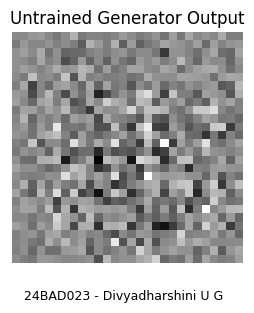

In [2]:
# ============================================================
# EXPT 8 - Generation of Synthetic Images using a GAN
# PART B: IMPLEMENTING THE GENERATOR AND DISCRIMINATOR
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers, models

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("-" * 50)

NOISE_DIM = 100   # size of the random noise vector

# 1. Build the Generator (noise -> 28x28x1 image)
def build_generator():
    model = models.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7 * 7 * 256, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 256)),

        layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),

        layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh"),
    ], name="generator")
    return model

# 2. Build the Discriminator (28x28x1 image -> real/fake score)
def build_discriminator():
    model = models.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 5, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),

        layers.Conv2D(128, 5, strides=2, padding="same"),
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1),   # raw logit: real vs fake
    ], name="discriminator")
    return model

generator = build_generator()
discriminator = build_discriminator()

# 3. Loss function and optimizers
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
gen_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
disc_optimizer = tf.keras.optimizers.Adam(1e-4, beta_1=0.5)
print("Loss function : Binary Cross-Entropy (from logits)")
print("Optimizer     : Adam (lr = 0.0001, beta_1 = 0.5)")
print("-" * 50)

# 4. Combine Generator and Discriminator to construct the GAN
gan_input = tf.keras.Input(shape=(NOISE_DIM,))
gan = tf.keras.Model(gan_input, discriminator(generator(gan_input)), name="gan")

# 5. Display model summaries
print("GENERATOR SUMMARY")
generator.summary()
print("\nDISCRIMINATOR SUMMARY")
discriminator.summary()
print("\nGAN (Generator + Discriminator) SUMMARY")
gan.summary()

# 6. Test the untrained Generator with random noise
noise = tf.random.normal([1, NOISE_DIM])
untrained_image = generator(noise, training=False)
decision = discriminator(untrained_image, training=False)
print("-" * 50)
print("Generated image shape        :", untrained_image.shape)
print("Discriminator score (logit)  :", float(decision[0][0]))

plt.figure(figsize=(3, 3))
plt.imshow(untrained_image[0, :, :, 0], cmap="gray")
plt.title("Untrained Generator Output")
plt.suptitle("24BAD023 - Divyadharshini U G", y=0.02, fontsize=9)
plt.axis("off")
plt.show()

Name    : Divyadharshini U G
Roll No : 24BAD023
--------------------------------------------------
GPU available: True
--------------------------------------------------
Epoch 01/20 | Generator loss: 0.6319 | Discriminator loss: 1.2950


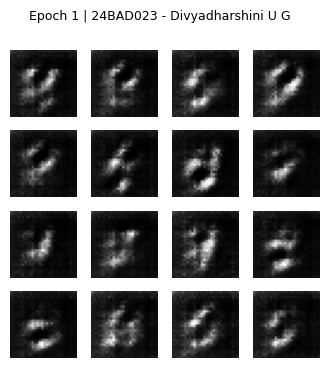

Epoch 02/20 | Generator loss: 0.7290 | Discriminator loss: 1.3062
Epoch 03/20 | Generator loss: 0.7440 | Discriminator loss: 1.3226
Epoch 04/20 | Generator loss: 0.7537 | Discriminator loss: 1.3231
Epoch 05/20 | Generator loss: 0.7682 | Discriminator loss: 1.3079


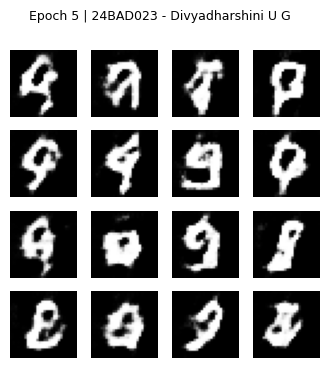

Epoch 06/20 | Generator loss: 0.7856 | Discriminator loss: 1.2936
Epoch 07/20 | Generator loss: 0.7729 | Discriminator loss: 1.3094
Epoch 08/20 | Generator loss: 0.7467 | Discriminator loss: 1.3407
Epoch 09/20 | Generator loss: 0.7413 | Discriminator loss: 1.3485
Epoch 10/20 | Generator loss: 0.7448 | Discriminator loss: 1.3475


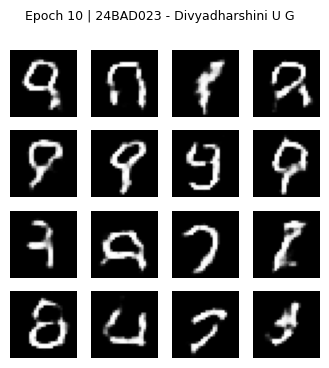

Epoch 11/20 | Generator loss: 0.7431 | Discriminator loss: 1.3462
Epoch 12/20 | Generator loss: 0.7390 | Discriminator loss: 1.3466
Epoch 13/20 | Generator loss: 0.7376 | Discriminator loss: 1.3471
Epoch 14/20 | Generator loss: 0.7456 | Discriminator loss: 1.3424
Epoch 15/20 | Generator loss: 0.7430 | Discriminator loss: 1.3428


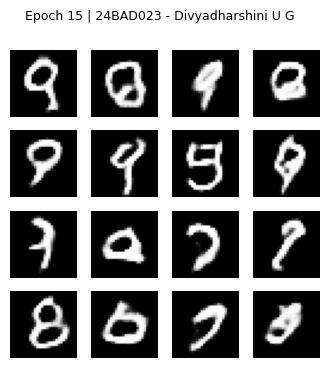

Epoch 16/20 | Generator loss: 0.7451 | Discriminator loss: 1.3407
Epoch 17/20 | Generator loss: 0.7450 | Discriminator loss: 1.3394
Epoch 18/20 | Generator loss: 0.7508 | Discriminator loss: 1.3366
Epoch 19/20 | Generator loss: 0.7514 | Discriminator loss: 1.3324
Epoch 20/20 | Generator loss: 0.7567 | Discriminator loss: 1.3314


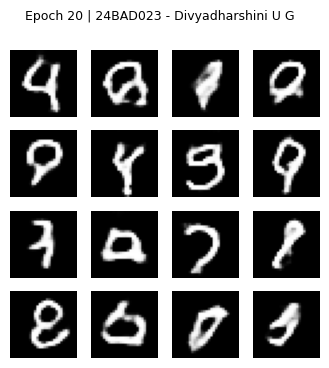

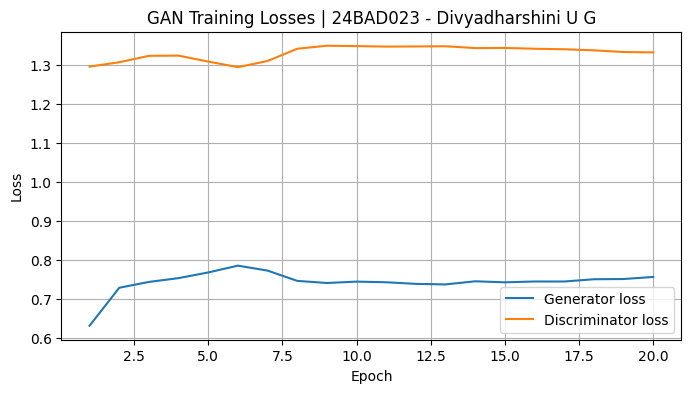

In [3]:
# ============================================================
# EXPT 8 - Generation of Synthetic Images using a GAN
# PART C: GAN TRAINING AND PERFORMANCE MONITORING
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("-" * 50)

# Check that Parts A and B were run in this session
required = ["NOISE_DIM", "generator", "discriminator", "cross_entropy",
            "gen_optimizer", "disc_optimizer", "train_dataset"]
missing = [name for name in required if name not in globals()]
if missing:
    raise NameError(f"Run Part A and Part B first. Missing: {missing}")

# Check for GPU
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", bool(gpus))
if not gpus:
    print("WARNING: no GPU found. Training will be slow. "
          "Use Runtime > Change runtime type > T4 GPU.")
print("-" * 50)

EPOCHS = 20
NUM_EXAMPLES = 16
seed = tf.random.normal([NUM_EXAMPLES, NOISE_DIM])   # fixed noise to track progress

# 1. Loss functions
def discriminator_loss(real_out, fake_out):
    real_loss = cross_entropy(tf.ones_like(real_out), real_out)
    fake_loss = cross_entropy(tf.zeros_like(fake_out), fake_out)
    return real_loss + fake_loss

def generator_loss(fake_out):
    return cross_entropy(tf.ones_like(fake_out), fake_out)

# 2. One training step (Discriminator and Generator updated on each batch)
@tf.function
def train_step(real_images):
    noise = tf.random.normal([tf.shape(real_images)[0], NOISE_DIM])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        fake_images = generator(noise, training=True)
        real_out = discriminator(real_images, training=True)
        fake_out = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_out)
        d_loss = discriminator_loss(real_out, fake_out)
    g_grads = gen_tape.gradient(g_loss, generator.trainable_variables)
    d_grads = disc_tape.gradient(d_loss, discriminator.trainable_variables)
    gen_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    disc_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss

# 3. Display generated images during training
def show_generated(epoch):
    preds = generator(seed, training=False)
    plt.figure(figsize=(4, 4))
    for i in range(NUM_EXAMPLES):
        plt.subplot(4, 4, i + 1)
        plt.imshow(preds[i, :, :, 0] * 127.5 + 127.5, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch} | 24BAD023 - Divyadharshini U G", fontsize=9)
    plt.show()

# 4. Training loop
g_losses, d_losses = [], []
for epoch in range(1, EPOCHS + 1):
    g_batch, d_batch = [], []
    for batch in train_dataset:
        g_l, d_l = train_step(batch)
        g_batch.append(float(g_l))
        d_batch.append(float(d_l))
    g_losses.append(np.mean(g_batch))
    d_losses.append(np.mean(d_batch))
    print(f"Epoch {epoch:02d}/{EPOCHS} | Generator loss: {g_losses[-1]:.4f} | Discriminator loss: {d_losses[-1]:.4f}")
    if epoch == 1 or epoch % 5 == 0:
        show_generated(epoch)

# 5. Plot Generator and Discriminator losses
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), g_losses, label="Generator loss")
plt.plot(range(1, EPOCHS + 1), d_losses, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Losses | 24BAD023 - Divyadharshini U G")
plt.legend()
plt.grid(True)
plt.show()

Name    : Divyadharshini U G
Roll No : 24BAD023
--------------------------------------------------
Generated images shape : (10, 28, 28, 1)
Real images shape      : (10, 28, 28)
Generated pixel range  : min = 0.0, max = 255.0
--------------------------------------------------


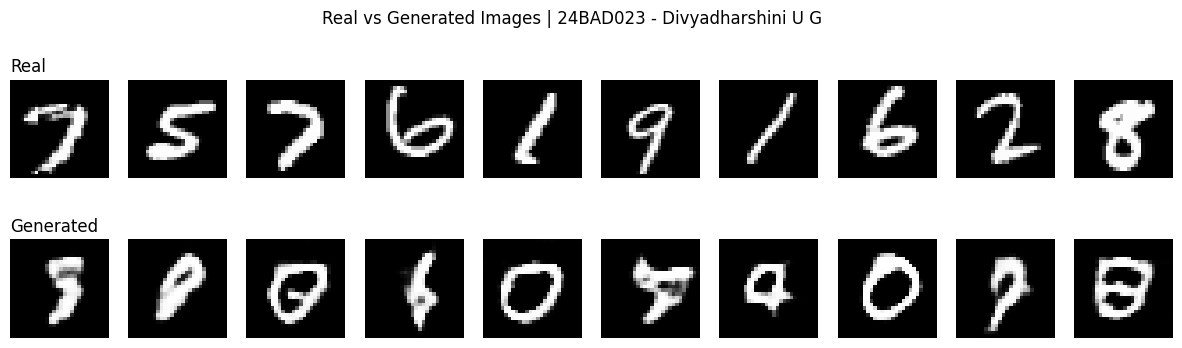

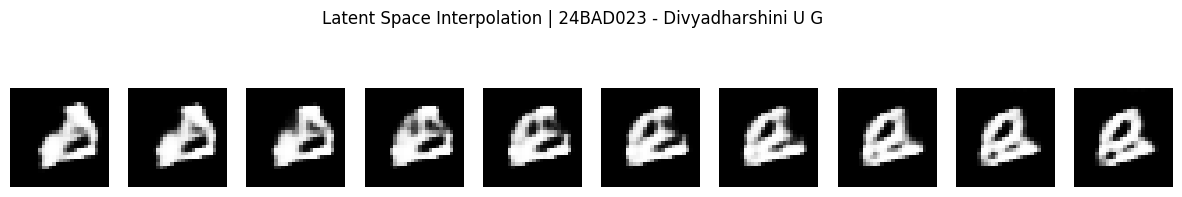

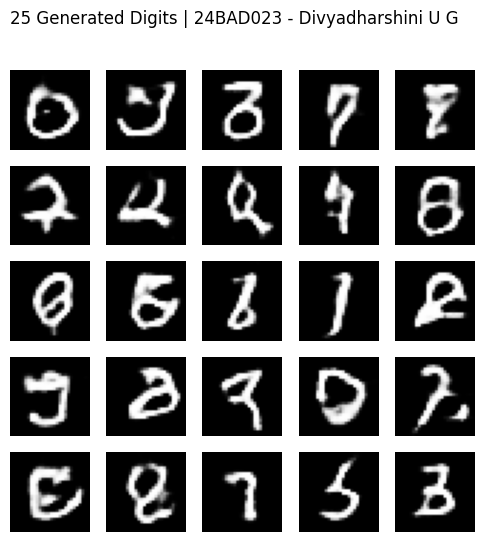

Models saved: generator.keras, discriminator.keras


In [4]:
# ============================================================
# EXPT 8 - Generation of Synthetic Images using a GAN
# PART D: GENERATING, COMPARING AND VISUALIZING IMAGES
# Name    : Divyadharshini U G
# Roll No : 24BAD023
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("Name    : Divyadharshini U G")
print("Roll No : 24BAD023")
print("-" * 50)

# 1. Generate new synthetic images from fresh random noise
n = 10
new_noise = tf.random.normal([n, NOISE_DIM])
generated = generator(new_noise, training=False).numpy()
generated = generated * 127.5 + 127.5          # scale back to 0-255

# 2. Pick random real images from the test set
idx = np.random.choice(len(x_test), n, replace=False)
real = x_test[idx].reshape(n, 28, 28) * 127.5 + 127.5

print("Generated images shape :", generated.shape)
print("Real images shape      :", real.shape)
print("Generated pixel range  : min = %.1f, max = %.1f" % (generated.min(), generated.max()))
print("-" * 50)

# 3. Compare real images (top row) with generated images (bottom row)
fig, axes = plt.subplots(2, n, figsize=(15, 3.8))
for i in range(n):
    axes[0, i].imshow(real[i], cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].imshow(generated[i, :, :, 0], cmap="gray")
    axes[1, i].axis("off")
axes[0, 0].set_title("Real", loc="left")
axes[1, 0].set_title("Generated", loc="left")
plt.suptitle("Real vs Generated Images | 24BAD023 - Divyadharshini U G", y=1.02)
plt.show()

# 4. Latent-space interpolation: smooth walk between two noise vectors
z1 = tf.random.normal([1, NOISE_DIM])
z2 = tf.random.normal([1, NOISE_DIM])
steps = 10
interp = tf.concat([z1 * (1 - a) + z2 * a for a in np.linspace(0, 1, steps)], axis=0)
interp_imgs = generator(interp, training=False).numpy() * 127.5 + 127.5

fig, axes = plt.subplots(1, steps, figsize=(15, 2.2))
for i in range(steps):
    axes[i].imshow(interp_imgs[i, :, :, 0], cmap="gray")
    axes[i].axis("off")
plt.suptitle("Latent Space Interpolation | 24BAD023 - Divyadharshini U G", y=1.08)
plt.show()

# 5. Grid of 25 generated images to judge quality and diversity
grid_noise = tf.random.normal([25, NOISE_DIM])
grid_imgs = generator(grid_noise, training=False).numpy() * 127.5 + 127.5
plt.figure(figsize=(6, 6))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(grid_imgs[i, :, :, 0], cmap="gray")
    plt.axis("off")
plt.suptitle("25 Generated Digits | 24BAD023 - Divyadharshini U G")
plt.show()

# 6. Save the trained models
generator.save("generator.keras")
discriminator.save("discriminator.keras")
print("Models saved: generator.keras, discriminator.keras")